In [10]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             log_loss, confusion_matrix, classification_report,
                             roc_curve, auc, cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define Project Paths
BASE_DIR = "/content/drive/MyDrive/AI_Image_Project"
FEATURES_DIR = os.path.join(BASE_DIR, "features")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONF_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CONF_DIR, exist_ok=True)

print("Loading optimized 500-feature matrices and strict split indices...")

# 3. Load Features, Labels, and Splits
X = np.load(os.path.join(FEATURES_DIR, "X_combined_500.npy"))
y = np.load(os.path.join(FEATURES_DIR, "y_labels_15k.npy"))

train_idx = np.load(os.path.join(FEATURES_DIR, "train_idx.npy"))
val_idx   = np.load(os.path.join(FEATURES_DIR, "val_idx.npy"))
test_idx  = np.load(os.path.join(FEATURES_DIR, "test_idx.npy"))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val     = X[val_idx], y[val_idx]
X_test, y_test   = X[test_idx], y[test_idx]

CLASS_NAMES = np.array(["Authentic", "Full AI", "Partial AI"])
print(f"Data ready. Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading optimized 500-feature matrices and strict split indices...
Data ready. Train: (12000, 500) | Val: (1500, 500) | Test: (1500, 500)


In [11]:
# Load pre-computed scaler parameters from Notebook 1 to prevent data leakage
scaler_path = os.path.join(FEATURES_DIR, "scaler_params.npz")
if os.path.exists(scaler_path):
    scaler = np.load(scaler_path)
    mu, sigma = scaler["mu"], scaler["sigma"]
    print("Loaded training scaler parameters.")
else:
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    sigma[sigma < 1e-8] = 1.0  # Prevent division by zero
    print("Calculated new scaler parameters.")

epsilon = 1e-8

# Apply Z-Score Normalization strictly using training stats
X_train_norm = (X_train - mu) / (sigma + epsilon)
X_val_norm   = (X_val - mu) / (sigma + epsilon)
X_test_norm  = (X_test - mu) / (sigma + epsilon)

print(f"Normalization verified. Train Mean: {np.mean(X_train_norm):.4f}, Train Std: {np.std(X_train_norm):.4f}")

Loaded training scaler parameters.
Normalization verified. Train Mean: -0.0000, Train Std: 1.0000


In [12]:
class RandomFourierFeatures:
    """
    Approximates the RBF (Gaussian) kernel using Random Fourier Features.
    Maps input data to a higher-dimensional space where linear SGD can learn non-linear boundaries.
    """
    def __init__(self, n_components=1000, gamma=0.1, random_state=42):
        self.n_components = n_components
        self.gamma = gamma
        self.random_state = random_state
        self.W = None
        self.b = None

    def fit(self, n_features):
        rng = np.random.default_rng(self.random_state)
        # W drawn from a Gaussian distribution with variance 2*gamma
        self.W = rng.normal(0, np.sqrt(2 * self.gamma), (n_features, self.n_components))
        # b drawn from a Uniform distribution between 0 and 2*pi
        self.b = rng.uniform(0, 2 * np.pi, self.n_components)
        return self

    def transform(self, X):
        # Projection: sqrt(2/D) * cos(XW + b)
        Z = np.dot(X, self.W) + self.b
        return np.sqrt(2.0 / self.n_components) * np.cos(Z)

class ScratchRBFSVM_OvR:
    """
    Non-Linear SVM from scratch using Random Fourier Features and OvR Mini-Batch SGD.
    Includes proper n_samples scaling for L2 regularization to prevent gradient explosion.
    """
    def __init__(self, C=1.0, gamma=0.1, n_components=1000, learning_rate=0.05, epochs=150, batch_size=256, decay=0.001, random_state=42):
        self.C = float(C)
        self.gamma = float(gamma)
        self.n_components = int(n_components)
        self.lr = float(learning_rate)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.decay = float(decay)
        self.random_state = random_state

        self.rff = None
        self.models = []
        self.classes_ = None
        self.train_loss_history = []
        self.val_loss_history = []

    def _compute_hinge_loss(self, X_mapped, y_binary, W, b, lambda_reg):
        n_samples = X_mapped.shape[0]
        distances = y_binary * (np.dot(X_mapped, W) + b)
        distances[distances > 1] = 1 # max(0, 1 - y*(wx+b))
        hinge = np.mean(1 - distances)
        # Scale L2 loss by n_samples to match gradient and prevent overflow
        l2 = (lambda_reg / (2 * n_samples)) * np.sum(W ** 2)
        return hinge + l2

    def fit(self, X, y, X_val=None, y_val=None, verbose=False):
        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)

        # 1. Fit RFF mapping and transform features
        self.rff = RandomFourierFeatures(n_components=self.n_components, gamma=self.gamma, random_state=self.random_state)
        self.rff.fit(n_features)

        X_mapped = self.rff.transform(X)
        if X_val is not None:
            X_val_mapped = self.rff.transform(X_val)

        lambda_reg = 1.0 / max(self.C, 1e-12)
        rng = np.random.default_rng(self.random_state)

        # Initialize W and b for each OvR model
        self.models = [{'W': rng.normal(0, 0.01, self.n_components), 'b': 0.0} for _ in range(n_classes)]
        y_ovr = np.where(y[:, None] == self.classes_, 1, -1)
        if X_val is not None:
            y_val_ovr = np.where(y_val[:, None] == self.classes_, 1, -1)

        step = 0
        for epoch in range(self.epochs):
            perm = rng.permutation(n_samples)
            X_shuffled = X_mapped[perm]
            y_ovr_shuffled = y_ovr[perm]

            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                X_batch = X_shuffled[start_idx:end_idx]
                y_batch_ovr = y_ovr_shuffled[start_idx:end_idx]
                b_size = X_batch.shape[0]

                current_lr = self.lr / (1.0 + self.decay * step)
                step += 1

                for k in range(n_classes):
                    W = self.models[k]['W']
                    b = self.models[k]['b']
                    y_b = y_batch_ovr[:, k]

                    distances = 1 - y_b * (np.dot(X_batch, W) + b)
                    mask = (distances > 0).astype(float)

                    # FIXED: Scaled L2 gradient by n_samples to prevent explosion
                    dW = (lambda_reg / n_samples) * W - np.dot(X_batch.T, y_b * mask) / b_size
                    db = -np.sum(y_b * mask) / b_size

                    self.models[k]['W'] -= current_lr * dW
                    self.models[k]['b'] -= current_lr * db

            if verbose and (epoch % 20 == 0 or epoch == self.epochs - 1):
                t_loss = sum(self._compute_hinge_loss(X_mapped, y_ovr[:, k], self.models[k]['W'], self.models[k]['b'], lambda_reg) for k in range(n_classes))
                self.train_loss_history.append(t_loss)
                if X_val is not None:
                    v_loss = sum(self._compute_hinge_loss(X_val_mapped, y_val_ovr[:, k], self.models[k]['W'], self.models[k]['b'], lambda_reg) for k in range(n_classes))
                    self.val_loss_history.append(v_loss)

        return self

    def decision_function(self, X):
        X_mapped = self.rff.transform(X)
        scores = np.zeros((X.shape[0], len(self.classes_)))
        for k in range(len(self.classes_)):
            scores[:, k] = np.dot(X_mapped, self.models[k]['W']) + self.models[k]['b']
        return scores

    def predict_proba(self, X):
        # NOTE: Uncalibrated pseudo-probabilities derived via a basic sigmoid
        # mapping of the margin distances. Standard SVM output is technically non-probabilistic.
        scores = self.decision_function(X)
        sigmoids = 1.0 / (1.0 + np.exp(-np.clip(scores, -50, 50)))
        return sigmoids / np.sum(sigmoids, axis=1, keepdims=True)

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

print("RBF-SVM via Random Fourier Features Initialized.")

RBF-SVM via Random Fourier Features Initialized.


Starting RBF Hyperparameter Tuning Grid Search...
C=0.1   | Gamma=0.001 | Val Macro-F1: 0.6787 | Time: 11.30s
C=0.1   | Gamma=0.01  | Val Macro-F1: 0.4587 | Time: 11.21s
C=0.1   | Gamma=0.05  | Val Macro-F1: 0.3882 | Time: 11.40s
C=0.1   | Gamma=0.1   | Val Macro-F1: 0.3717 | Time: 11.35s
C=1.0   | Gamma=0.001 | Val Macro-F1: 0.6829 | Time: 11.35s
C=1.0   | Gamma=0.01  | Val Macro-F1: 0.4605 | Time: 11.42s
C=1.0   | Gamma=0.05  | Val Macro-F1: 0.3883 | Time: 11.78s
C=1.0   | Gamma=0.1   | Val Macro-F1: 0.3708 | Time: 11.45s
C=10.0  | Gamma=0.001 | Val Macro-F1: 0.6824 | Time: 11.85s
C=10.0  | Gamma=0.01  | Val Macro-F1: 0.4600 | Time: 11.69s
C=10.0  | Gamma=0.05  | Val Macro-F1: 0.3884 | Time: 11.40s
C=10.0  | Gamma=0.1   | Val Macro-F1: 0.3716 | Time: 11.32s
C=100.0 | Gamma=0.001 | Val Macro-F1: 0.6824 | Time: 11.20s
C=100.0 | Gamma=0.01  | Val Macro-F1: 0.4600 | Time: 11.27s
C=100.0 | Gamma=0.05  | Val Macro-F1: 0.3889 | Time: 11.34s
C=100.0 | Gamma=0.1   | Val Macro-F1: 0.3723 | Tim

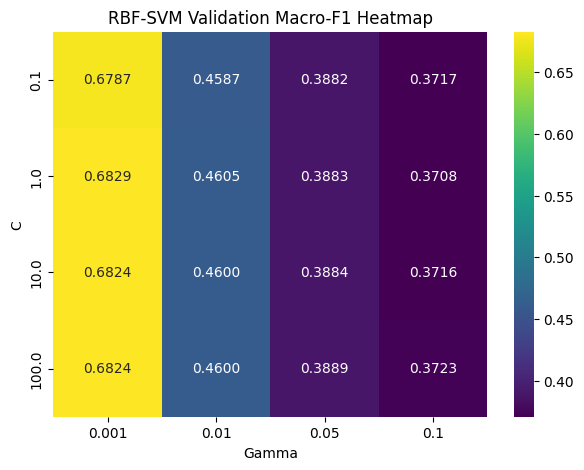

In [13]:
# Extended grid to ensure we don't hit edge boundaries
C_candidates = [0.1, 1.0, 10.0, 100.0]
gamma_candidates = [0.001, 0.01, 0.05, 0.1]
tuning_results = []

print("Starting RBF Hyperparameter Tuning Grid Search...")
# Using 150 epochs for tuning to match the Logistic Regression notebook
for c_val in C_candidates:
    for g_val in gamma_candidates:
        t0 = time.time()
        # Keep n_components moderate during tuning for speed
        temp_model = ScratchRBFSVM_OvR(C=c_val, gamma=g_val, n_components=1000, epochs=150, learning_rate=0.05)

        # Safely suppress overflow warnings and check for divergence
        with np.errstate(all='ignore'):
            temp_model.fit(X_train_norm, y_train)

        if any(np.isnan(m['W']).any() for m in temp_model.models):
            print(f"C={c_val:<5} | Gamma={g_val:<5} | Skipped due to divergence/overflow.")
            continue

        val_preds = temp_model.predict(X_val_norm)
        val_f1 = f1_score(y_val, val_preds, average='macro')

        elapsed = time.time() - t0
        tuning_results.append({"C": c_val, "Gamma": g_val, "Val_F1": val_f1, "Time (s)": elapsed})
        print(f"C={c_val:<5} | Gamma={g_val:<5} | Val Macro-F1: {val_f1:.4f} | Time: {elapsed:.2f}s")

df_tune = pd.DataFrame(tuning_results)
best_config = df_tune.sort_values(by="Val_F1", ascending=False).iloc[0]
best_c, best_gamma = best_config["C"], best_config["Gamma"]

print("\n" + "="*40)
print(f"Optimal Configuration Selected: C = {best_c}, Gamma = {best_gamma}")
print("="*40)

if best_c in [min(C_candidates), max(C_candidates)] or best_gamma in [min(gamma_candidates), max(gamma_candidates)]:
    print(f"⚠️ WARNING: The best parameter(s) lie at the edge of the search grid. Consider expanding the grid limits.")

# Tuning Heatmap
pivot_table = df_tune.pivot(index="C", columns="Gamma", values="Val_F1")
plt.figure(figsize=(7, 5))
sns.heatmap(pivot_table, annot=True, fmt=".4f", cmap="viridis")
plt.title("RBF-SVM Validation Macro-F1 Heatmap")
plt.show()

Training Final RBF-SVM with C=1.0, Gamma=0.001, N_Features=2000...
Final training finished in 44.52 seconds.


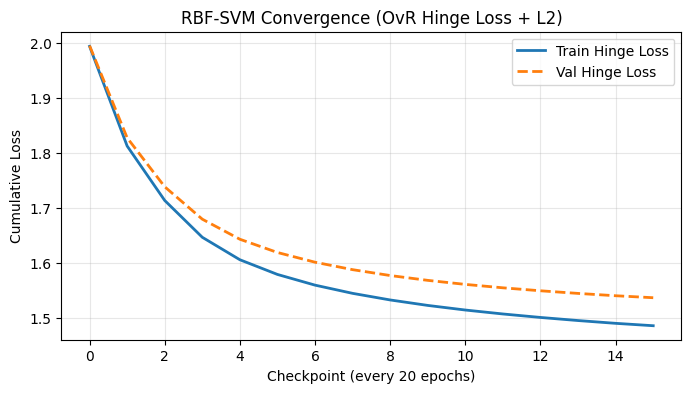

In [14]:
print(f"Training Final RBF-SVM with C={best_c}, Gamma={best_gamma}, N_Features=2000...")
# Scaling up RFF components for the final training run to boost accuracy
# Using 300 epochs for the final training to match the Logistic Regression notebook
final_rbf_svm = ScratchRBFSVM_OvR(
    C=best_c,
    gamma=best_gamma,
    n_components=2000,
    epochs=300,
    learning_rate=0.05
)

start_t = time.time()
final_rbf_svm.fit(X_train_norm, y_train, X_val=X_val_norm, y_val=y_val, verbose=True)
train_time = time.time() - start_t
print(f"Final training finished in {train_time:.2f} seconds.")

# Plot Sub-Gradient Descent Convergence
plt.figure(figsize=(8, 4))
plt.plot(final_rbf_svm.train_loss_history, label='Train Hinge Loss', lw=2)
plt.plot(final_rbf_svm.val_loss_history, label='Val Hinge Loss', lw=2, linestyle='--')
plt.title("RBF-SVM Convergence (OvR Hinge Loss + L2)")
plt.xlabel("Checkpoint (every 20 epochs)")
plt.ylabel("Cumulative Loss")
plt.legend()
plt.grid(True, alpha=0.3)
# Note: If the loss curve appears highly noisy, consider lowering the learning rate or increasing the decay parameter.
plt.show()

FINAL TEST EVALUATION METRICS (RBF-SVM)
Model               : RBF-SVM (Scratch RFF OvR)
Accuracy (%)        : 74.4
Macro F1            : 0.7323
Weighted F1         : 0.7323
ROC-AUC (OvR)       : 0.8978
Log Loss            : 0.868
Cohen's Kappa       : 0.616
MCC                 : 0.6238
Train Time (s)      : 44.52

              precision    recall  f1-score   support

   Authentic       0.73      0.51      0.60       500
     Full AI       0.81      0.98      0.89       500
  Partial AI       0.68      0.75      0.71       500

    accuracy                           0.74      1500
   macro avg       0.74      0.74      0.73      1500
weighted avg       0.74      0.74      0.73      1500



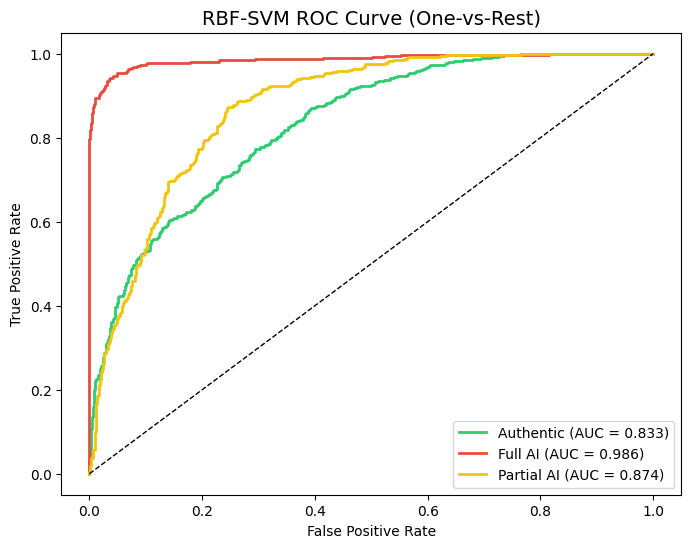

In [15]:
# Single test evaluation. Do not tune after this.
print("=" * 60)
print("FINAL TEST EVALUATION METRICS (RBF-SVM)")
print("=" * 60)

y_test_pred = final_rbf_svm.predict(X_test_norm)
y_test_prob = final_rbf_svm.predict_proba(X_test_norm)
y_test_scores = final_rbf_svm.decision_function(X_test_norm) # Raw margins for ROC
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# ROC-AUC (One-vs-Rest) computed strictly on raw margins, not pseudo-probabilities
auc_scores_ovr = [roc_auc_score(y_test_bin[:, k], y_test_scores[:, k]) for k in range(len(CLASS_NAMES))]
macro_roc_auc = np.mean(auc_scores_ovr)

metrics_dict = {
    "Model": "RBF-SVM (Scratch RFF OvR)",
    "Accuracy (%)": round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "Macro F1": round(f1_score(y_test, y_test_pred, average='macro'), 4),
    "Weighted F1": round(f1_score(y_test, y_test_pred, average='weighted'), 4),
    "ROC-AUC (OvR)": round(macro_roc_auc, 4),
    "Log Loss": round(log_loss(y_test, y_test_prob), 4),
    "Cohen's Kappa": round(cohen_kappa_score(y_test, y_test_pred), 4),
    "MCC": round(matthews_corrcoef(y_test, y_test_pred), 4),
    "Train Time (s)": round(train_time, 2)
}

# NOTE: SVM Log Loss is computed from uncalibrated pseudo-probabilities and is
# NOT directly comparable to the Logistic Regression Log Loss.
for k, v in metrics_dict.items():
    print(f"{k:<20}: {v}")
print("\n" + classification_report(y_test, y_test_pred, target_names=CLASS_NAMES))

# ROC Curves Plot (from raw decision_function scores)
plt.figure(figsize=(8, 6))
colors = ['#2ecc71', '#e74c3c', '#f1c40f']
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_scores[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{CLASS_NAMES[i]} (AUC = {auc_scores_ovr[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title("RBF-SVM ROC Curve (One-vs-Rest)", fontsize=14)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

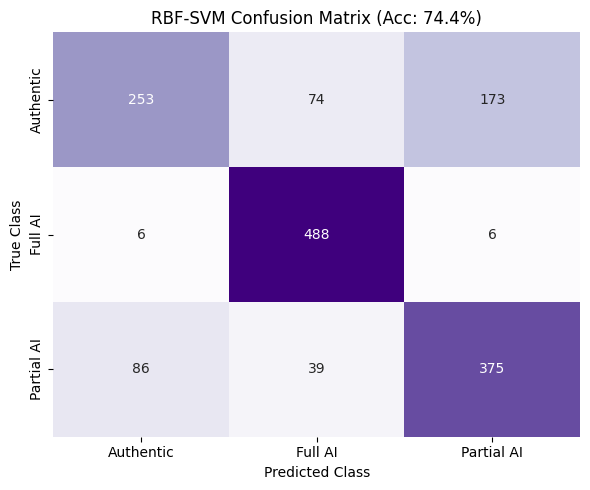

In [16]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.title(f"RBF-SVM Confusion Matrix (Acc: {metrics_dict['Accuracy (%)']}%)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig(os.path.join(CONF_DIR, "svm_rbf_cm_15k.png"), dpi=200)
plt.show()

In [17]:
# 1. Save Model Parameters (SVM W/b, RFF W/b, Hyperparameters, and Class Names)
model_save_path = os.path.join(MODELS_DIR, "svm_rbf_model.npz")
W_all = np.array([m['W'] for m in final_rbf_svm.models])
b_all = np.array([m['b'] for m in final_rbf_svm.models])

np.savez(model_save_path,
         W=W_all,
         b=b_all,
         rff_W=final_rbf_svm.rff.W,
         rff_b=final_rbf_svm.rff.b,
         best_c=best_c,
         best_gamma=best_gamma,
         best_lr=final_rbf_svm.lr,
         class_names=CLASS_NAMES)
print(f"RBF-SVM parameters saved to: {model_save_path}")

# 2. Optional: saved probabilities for any later analysis.
np.save(os.path.join(MODELS_DIR, "svm_rbf_val_probs.npy"), final_rbf_svm.predict_proba(X_val_norm))
np.save(os.path.join(MODELS_DIR, "svm_rbf_test_probs.npy"), y_test_prob)

# 3. Append Metrics to tracking CSV
csv_path = os.path.join(RESULTS_DIR, "model_comparison_15k.csv")
if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    # Overwrite if model already present, else append
    df_results = df_results[df_results["Model"] != metrics_dict["Model"]]
    df_results = pd.concat([df_results, pd.DataFrame([metrics_dict])], ignore_index=True)
else:
    df_results = pd.DataFrame([metrics_dict])

df_results.to_csv(csv_path, index=False)
print(f"Metrics appended to: {csv_path}")

RBF-SVM parameters saved to: /content/drive/MyDrive/AI_Image_Project/saved_models/svm_rbf_model.npz
Metrics appended to: /content/drive/MyDrive/AI_Image_Project/results/model_comparison_15k.csv


In [18]:
def predict_rbf_from_saved(path, X_normalized):
    """
    Loads saved model parameters and generates predictions exactly as the live model does.
    Returns integer indices ensuring perfect compatibility with voting ensembles.
    """
    data = np.load(path, allow_pickle=True)
    W = data['W']             # Shape: (3, n_components)
    b = data['b']             # Shape: (3,)
    rff_W = data['rff_W']     # Shape: (n_features, n_components)
    rff_b = data['rff_b']     # Shape: (n_components,)

    # 1. Apply RFF Transformation: sqrt(2/D) * cos(XW + b)
    n_components = rff_W.shape[1]
    Z = np.dot(X_normalized, rff_W) + rff_b
    X_mapped = np.sqrt(2.0 / n_components) * np.cos(Z)

    # 2. Compute raw decision scores: X_mapped @ W.T + b
    decision_scores = np.dot(X_mapped, W.T) + b

    # 3. Determine predicted class via argmax (returns integer indices 0, 1, 2)
    predicted_indices = np.argmax(decision_scores, axis=1)

    return predicted_indices, decision_scores

# Do not tune after this point.
print("Testing standalone prediction function on test set...")
saved_preds, saved_scores = predict_rbf_from_saved(model_save_path, X_test_norm)
live_preds = final_rbf_svm.predict(X_test_norm)

# Validate that the standalone function yields the exact same predictions
assert np.array_equal(saved_preds, live_preds), "Mismatch in predicted labels between saved model and live model!"
print("Success! Standalone function predictions match the live trained RBF model perfectly.")

Testing standalone prediction function on test set...
Success! Standalone function predictions match the live trained RBF model perfectly.
